# Notebook 03 — Train & Evaluate
## STOP 7 — Model Architecture

In [1]:
from pathlib import Path
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
CHARTS = ROOT / "charts"
MODELS.mkdir(parents=True, exist_ok=True)
CHARTS.mkdir(parents=True, exist_ok=True)

arr = np.load(PROC / "dataset_arrays.npz")
X_train, X_val, X_test = arr["X_train"], arr["X_val"], arr["X_test"]
y_train, y_val, y_test = arr["y_train"], arr["y_val"], arr["y_test"]

train_loader = DataLoader(TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)), batch_size=64, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)), batch_size=64, shuffle=False)

class HouseANN(nn.Module):
    def __init__(self, input_dim=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

model = HouseANN(input_dim=X_train.shape[1])

## STOP 8 — Loss Functions Comparison

In [2]:
mse = nn.MSELoss()
mae = nn.L1Loss()
huber = nn.HuberLoss(delta=1.0)

xb, yb = next(iter(train_loader))
pred = model(xb)
print("MSE:", float(mse(pred, yb)))
print("MAE:", float(mae(pred, yb)))
print("Huber:", float(huber(pred, yb)))

MSE: 6.482086658477783
MAE: 2.2506422996520996
Huber: 1.7526177167892456


## STOP 9 — Custom Loss Function

In [3]:
class WeightedMSELoss(nn.Module):
    def forward(self, y_pred, y_true):
        w = torch.where(y_pred < y_true, 2.0, 1.0)
        return torch.mean(w * (y_pred - y_true) ** 2)

weighted_mse = WeightedMSELoss()
print("WeightedMSE sample:", float(weighted_mse(pred, yb)))

WeightedMSE sample: 12.964173316955566


## STOP 10 — Training with Checkpointing

In [4]:
criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=150)

best_val = float("inf")
history = {"train_loss": [], "val_loss": [], "lr": []}

for epoch in range(1, 151):
    model.train()
    tr_loss, tr_n = 0.0, 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * yb.size(0)
        tr_n += yb.size(0)

    model.eval()
    va_loss, va_n = 0.0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            out = model(xb)
            loss = criterion(out, yb)
            va_loss += loss.item() * yb.size(0)
            va_n += yb.size(0)

    tr = tr_loss / tr_n
    va = va_loss / va_n
    history["train_loss"].append(tr)
    history["val_loss"].append(va)
    history["lr"].append(optimizer.param_groups[0]["lr"])

    if va < best_val:
        best_val = va
        torch.save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "best_val_loss": best_val,
        }, MODELS / "checkpoint_best.pth")

    scheduler.step()

ckpt = torch.load(MODELS / "checkpoint_best.pth", map_location="cpu")
model.load_state_dict(ckpt["model_state"])
print("Loaded best checkpoint from epoch", ckpt["epoch"], "val_loss", ckpt["best_val_loss"])

Loaded best checkpoint from epoch 49 val_loss 0.1273992374767976


## STOP 11 + STOP 12 — Evaluation Metrics & LR Scheduler Plot

{'mse': 0.27186904945840945, 'rmse': 0.521410634201499, 'mae': 0.34797649282615545, 'r2': 0.7925311459381148}


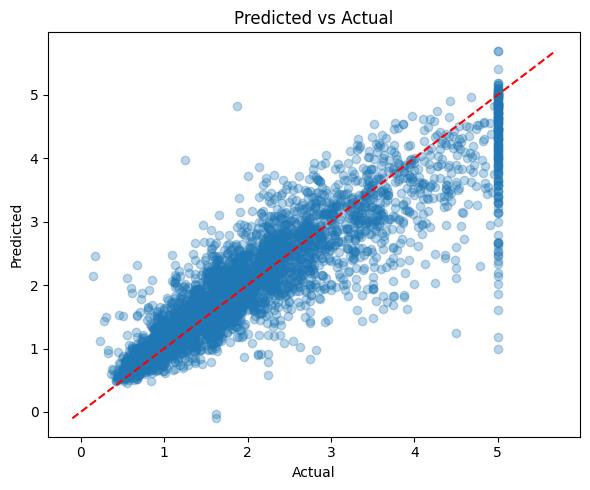

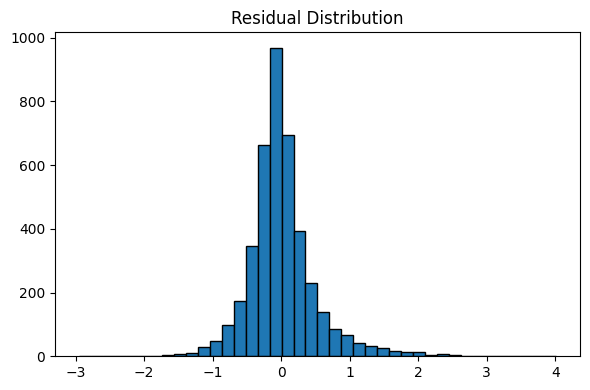

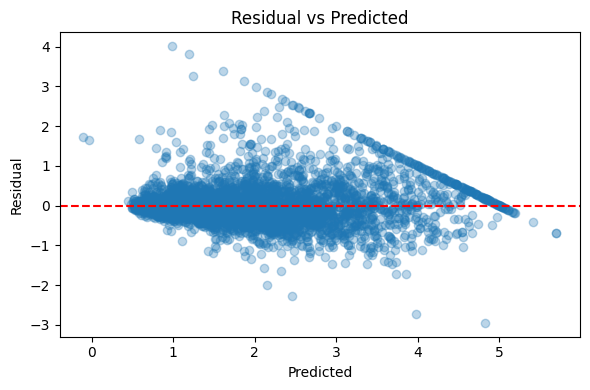

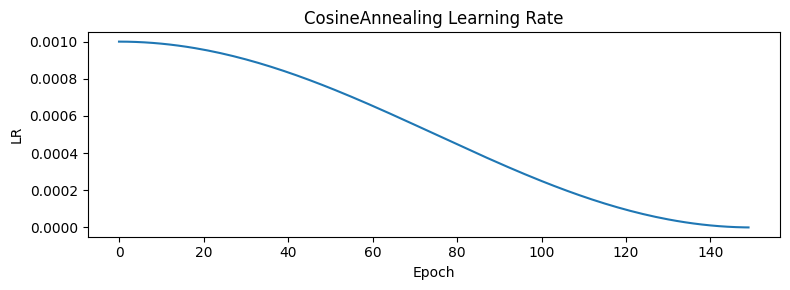

In [7]:
model.eval()
y_pred = []
y_true = []
with torch.no_grad():
    for xb, yb in test_loader:
        out = model(xb).squeeze(1)
        y_pred.extend(out.cpu().numpy().tolist())
        y_true.extend(yb.squeeze(1).cpu().numpy().tolist())

y_pred = np.array(y_pred)
y_true = np.array(y_true)

mse_val = mean_squared_error(y_true, y_pred)
rmse_val = float(np.sqrt(mse_val))
mae_val = mean_absolute_error(y_true, y_pred)
r2_val = r2_score(y_true, y_pred)

metrics = {"mse": float(mse_val), "rmse": float(rmse_val), "mae": float(mae_val), "r2": float(r2_val)}
print(metrics)

plt.figure(figsize=(6,5))
plt.scatter(y_true, y_pred, alpha=0.3)
mn = min(y_true.min(), y_pred.min()); mx = max(y_true.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx], 'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Predicted vs Actual")
plt.tight_layout()
plt.savefig(CHARTS / "pred_vs_actual.png", dpi=180)
plt.show()

res = y_true - y_pred
plt.figure(figsize=(6,4))
plt.hist(res, bins=40, edgecolor='black')
plt.title("Residual Distribution")
plt.tight_layout()
plt.savefig(CHARTS / "residual_hist.png", dpi=180)
plt.show()

plt.figure(figsize=(6,4))
plt.scatter(y_pred, res, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual vs Predicted")
plt.tight_layout()
plt.savefig(CHARTS / "residual_vs_pred.png", dpi=180)
plt.show()

plt.figure(figsize=(8,3))
plt.plot(history["lr"])
plt.title("CosineAnnealing Learning Rate")
plt.xlabel("Epoch")
plt.ylabel("LR")
plt.tight_layout()
plt.savefig(CHARTS / "lr_schedule.png", dpi=180)
plt.show()

## STOP 13 — Save Final Model

In [8]:
torch.save(model.state_dict(), MODELS / "model.pkl")
(MODELS / "results.json").write_text(json.dumps(metrics, indent=2))
(PROC / "training_history.json").write_text(json.dumps(history, indent=2))

with open(PROC / "scaler.pkl", "rb") as f:
    scaler = pickle.load(f)

def predict_price(features_dict):
    order = ["MedInc","HouseAge","AveRooms","AveBedrms","Population","AveOccup","Latitude","Longitude"]
    x = np.array([[features_dict[k] for k in order]], dtype=np.float32)
    x = scaler.transform(x)
    x_t = torch.tensor(x, dtype=torch.float32)
    with torch.no_grad():
        out = model(x_t).squeeze().item()
    return float(out)

print("Model and artifacts saved.")

Model and artifacts saved.
